<h2 style="text-align:center; font-weight: bold">Analysis on Sports Preference through news outlet across the world.</h2>
<h4 style="text-align:center; font-weight: bold">Project Proposal</h4>

<h3>1. Aims, objectives and background</h3>
<h4>1.1 Introduction</h4>
With the invention of the internet, access to the vast information highway has transformed the media landscape, compelling it to adapt to the new digital world. Even before the advent of the internet, media played a crucial role in shaping public perception and understanding of events. However, the internet has significantly amplified this influence by providing real-time access to global happenings. Despite covering the same sports events, the frequency and emphasis on specific sports can vary significantly between local and global news outlets. This project aims to analyze and compare the frequency of sports news coverage across various news outlets worldwide to uncover patterns, differences, and similarities in sports preferences in different regions.<br><br>

This project will employ several methods to analyze a diverse range of sports articles from both local and global news outlets. We will scrape text from articles across different news outlets, both local and global, and examine the frequency of coverage of specific sports. The data will be sourced from news outlets in multiple countries, where English is predominantly used. By selecting three well-known news outlets from each country, we aim to provide a more accurate representation of sports preferences among the populace.
<h3 style="font-weight: bold"h3>1.2 Aims and objectives</h3>
Within this project, I would like to explore the following:
<ul>
  <li>Data Collection and Preprocessing
    <ul>
      <li>To gather dataset of articles from selected local and global news outlets to see the differences between the two</li>
      <li>To clean and preprocess the text data to ensure accuracy and consistency in the analysis</li>
    </ul>
  </li>
  <li>Frequency Analysis
    <ul>
      <li>To perform word frequency analysis on the datasets to identify the most commonly mentioned sports in local and global news</li>
      <li>To create comparative visualizations, such as word clouds and bar charts, to highlight differences between the outlet.s</li>
    </ul>
  </li>
</ul>
<h3 style="font-weight: bold">1.3 Data</h3>
<h4 style="font-weight: bold">1.3.1 Data Requirements</h4>
Three publications were chosen from each country, allowing a reasonable sample size from each country's publication. Choosing 3 types of article topics from each news publication (alternative are chosen if none are found for the particular news outlet). This allow for similar topics while having enough sample of article from each country to explore the similarity and differences. About 130 articles are chosen from each news publication which would be allow for about 100 to 200 articles for each country.
<h4 style="font-weight: bold">1.3.2 Choice of news outlet</h4>
In order to represent each country's publication outlet accurately, news outlet are chosen by the popularity of said news outlet within the country:
<ul>
  <li><h4>Local</h4>
        <ul>
            <li>The Straits Times: Leading the ranks as the top Singaporean web publisher, The Straits Times boasts an impressive 3.2 million engagements.[1]</li>
            <li>Channel News Asia: Holding the 3rd spot, Channel News Asia achieves a substantial 1.6 million engagements [1]</li>
        </ul>
  </li>
    <li><h4>UK</h4>
        <ul>
            <li>Daily Mail: Ranked 5th in influence score, the Daily Mail stands among the top media outlets [2]</li>
            <li>The Guardian: Holding the 2nd position in influence score, The Guardian is a prominent media outlet [2]</li>
        </ul>
    </li>
     <li><h4>US</h4>
        <ul>
            <li>CNN Sport: CNN is a globally recognized news network with a strong reputation for accurate and in-depth reporting. CNN Sport is known for its comprehensive coverage of sports events, providing detailed analysis and up-to-date information.</li>
            <li>Fox News: Fox News is one of the most-watched cable news networks, ensuring that its sports coverage reaches a broad and engaged audience.</li>
            <li>theScore: theScore is highly regarded for its specialized focus on sports, offering detailed, real-time updates, and live coverage. This makes it a go-to source for sports enthusiasts looking for the latest news and in-depth analysis.</li>
        </ul>
    </li>
</ul>
<h4 style="font-weight: bold">1.3.3 How news outlet and articles are selected.</h4>
The selection of news outlets for this analysis is meticulously curated based on their ratings and representation among their peers. This careful selection ensures that the chosen outlets accurately reflect the country's perspectives and public discourse. High-rated news outlets are more likely to influence and represent national sentiment, making their articles valuable for this comparative study.<br>

To achieve a comprehensive and accurate representation of word usage in sports coverage, articles are scraped from various categories within the sports section, including "game reports," "player interviews," "opinion pieces," and "feature stories." This diverse selection captures a wide range of topics and writing styles, enabling a thorough comparison between local and global sports news outlets. By including multiple categories, we ensure that the analysis covers different types of content, from factual reporting on games to subjective opinions on players and teams, thus providing a holistic view of the language and themes prevalent in sports news in each country.<br>

This method of selection and categorization facilitates a more accurate comparison and provides deeper insights into the word usage and thematic focus between local and global sports coverage.
<h3 style="font-weight: bold">1.4 Ethical considerations</h3>
<h4 style="font-weight: bold">1.4.1 Ethical consideration on articles</h4>
Ethical consideration have been considered, making sure each of the website ensuring all links that had been scrapped from each of the website have not been disallowed under the robot.txt of each site.
<h4 style="font-weight: bold">1.4.2 Potential issue that may result from this analysis.</h4>
Due to the nature of a smaller data sample size, data could be skewed from multiple outlier data that have been scraped, causing inaccurate analysis and outcome due to unusually high word count or an atypical usage of certain keywords. Moreover, small sample sizes limit the ability to generalize findings to the broader population. The variability introduced by outliers becomes more pronounced, reducing the statistical power of the analysis and increasing the margin of error. This lack of representativeness and robustness can undermine the reliability and validity of the research outcomes. <br><br>
Therefore, it is crucial to acknowledge and account for the limitations imposed by small sample sizes in data analysis.

<h3>2. Webscraping</h3>
<h4>2.1 Preparing requirements for web scraping</h4>

In [7]:
import os
import requests
from bs4 import BeautifulSoup
import pandas as pd
from urllib.parse import urljoin

# Specify headers to accept gzip encoding
headers = {
    'Accept-Encoding': 'gzip, deflate',
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'
}

<h4>2.2 Defining scraping and extraction functions</h4>

The script scrapes URLs of articles from specified sections of the Daily Mail website and saves them into a CSV file.

## Key Steps

1. **Define Sections to Scrape:**
    - `sections` is a list of sections to scrape URLs from. In this case, it is set to `['sport']`.

2. **Base URL Template:**
    - `base_url_template` is the URL template for the Daily Mail website sections.

3. **CSV File Path:**
    - `csv_file` is the path where the extracted URLs will be saved.

4. **Function to Scrape a Single Section:**
    - `scrape_section(section)` is a function that takes a section name, constructs the URL, sends a GET request, and extracts article URLs.
    - It uses BeautifulSoup to parse the HTML content and find all anchor tags with an `href` attribute.
    - It filters and constructs full URLs for article links and returns a list of up to 100 unique URLs.

5. **Function to Save URLs to CSV:**
    - `save_to_csv(urls, file_name)` takes a list of URLs and a file name, and saves the URLs to a CSV file.
    - If the file already exists, it appends the URLs; otherwise, it creates a new file.

6. **Ensure Directory Exists:**
    - `os.makedirs(os.path.dirname(csv_file), exist_ok=True)` ensures that the directory for the output file exists.

7. **Loop Through Sections to Scrape URLs:**
    - The script loops through the specified sections, scrapes URLs, and collects all unique URLs in a set.
    - Finally, it saves the collected URLs to the specified CSV file.

<h3>Local</h3>

<h4>Scraping article links from The Straits Time webpage</h4>

In [4]:
# Sections to scrape
sections = ['sport']

# Base URL template for the website
base_url_template = 'https://www.straitstimes.com/{}/latest?page='

# CSV file to save the extracted URLs
csv_file = 'scrape_link/local/strait_times_links.csv'

# Function to scrape a single page
def scrape_page(url):
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        # print(f'Successfully fetched {url}')
        soup = BeautifulSoup(response.content, 'html.parser')
        identifier = soup.find_all(class_='stretched-link')
        urls = [urljoin('https://www.straitstimes.com', link.get('href')) for link in identifier if link.get('href')]
        return urls
    else:
        print(f'Failed to fetch {url}. Status code: {response.status_code}')
        return []

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Loop through sections and pages to scrape URLs
for section in sections:
    base_url = base_url_template.format(section)
    for page_number in range(1,11):  # Change the range as needed
        page_url = base_url + str(page_number)
        urls = scrape_page(page_url)
        if urls:
            save_to_csv(urls, csv_file)

print('Extracted URLs have been saved to', csv_file)

Extracted URLs have been saved to scrape_link/local/strait_times_links.csv


<h4>Scraping article links from Channel News Asia webpage</h4>

In [19]:
# Sections to scrape
sections = ['sport']

# Base URL template for the website
base_url_template = 'https://www.channelnewsasia.com/{}'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/local/cna_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    session = requests.Session()
    urls = []

    # Define headers to mimic a browser request
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
        'Referer': url,
    }

    page_number = 1
    max_pages = 5  # Limit to 5 pages

    while page_number <= max_pages:
        params = {'page': page_number}
        response = session.get(url, headers=headers, params=params)

        if response.status_code == 200:
            soup = BeautifulSoup(response.content, 'html.parser')
            identifier = soup.find_all(class_='h6__link list-object__heading-link')
            page_urls = [urljoin('https://www.channelnewsasia.com', link.get('href')) for link in identifier if
                         link.get('href') and 'watch' not in link.get('href') and 'interactive' not in link.get(
                             'href') and 'listen' not in link.get('href')]
            urls.extend(page_urls)
            page_number += 1
        else:
            print(f'Failed to fetch page {page_number}. Status code: {response.status_code}')
            break

    return urls

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Sections to scrape
sections = ['sport']

# Loop through sections to scrape URLs
for section in sections:
    urls = scrape_section(section)
    if urls:
        save_to_csv(urls, csv_file)

print('Extracted URLs have been saved to', csv_file)


Extracted URLs have been saved to scrape_link/local/cna_links.csv


<h3>UK</h3>

<h4>Scraping article links from The Daily Mail webpage</h4>

In [7]:
# Sections to scrape
sections = ['sport']
# sections = ['news']

# Base URL template for the website
base_url_template = 'https://www.dailymail.co.uk/{}/index.html'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/uk/the_dailymail_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        print(f'Successfully fetched section {section}')
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute
        links = soup.find_all('a', href=True)
        # Use a set to avoid duplicate URLs
        urls = {urljoin('https://www.dailymail.co.uk/', link['href']) for link in links if '/article' in link['href']}
        return list(urls)[:100]  # Limit to the first 35 URLs
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return []

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Loop through sections to scrape URLs
all_urls = set()
for section in sections:
    urls = scrape_section(section)
    all_urls.update(urls)

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)


Successfully fetched section sport
Extracted URLs have been saved to scrape_link/uk/the_dailymail_links.csv


<h4>Scraping article links from The Guardian webpage</h4>

In [8]:
# Sections to scrape
sections = ['uk/sport']

# Base URL template for the website
base_url_template = 'https://www.theguardian.com/{}'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/uk/the_guardian_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url, headers=headers)
    
    if response.status_code == 200:
        print(f'Successfully fetched section {section}')
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute
        links = soup.find_all('a', href=True)
        # Use a set to avoid duplicate URLs
        urls = {urljoin('https://www.theguardian.com/', link['href']) for link in links if '/article' in link['href']}
        return urls
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return set()

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(urls, columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Loop through sections to scrape URLs
all_urls = set()
for section in sections:
    urls = scrape_section(section)
    all_urls.update(urls)

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)

Successfully fetched section uk/sport
Extracted URLs have been saved to scrape_link/uk/the_guardian_links.csv


<h3>US</h3>

<h4>Scraping article links from Fox News webpage</h4>

In [79]:
# URL to scrape
url = 'https://www.foxnews.com/sports'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/us/fox_news_sports_links.csv'

# Function to scrape the sports section
def scrape_sports_section(url):
    response = requests.get(url)
    
    if response.status_code == 200:
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute containing '/sports' immediately after the main URL
        links = soup.find_all('a', href=True)
        urls = set()
        for link in links:
            href = link['href']
            # Check if the link contains '/sports/' immediately following the main URL
            if href.startswith('/sports/'):
                full_url = urljoin('https://www.foxnews.com', href)
                urls.add(full_url)
        return urls
    else:
        print(f'Failed to fetch {url}. Status code: {response.status_code}')
        return set()

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        print('No URLs to save.')
        return
    
    urls_df = pd.DataFrame(list(urls), columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Scrape the sports section and save URLs
all_urls = scrape_sports_section(url)
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)


Extracted URLs have been saved to scrape_link/us/fox_news_sports_links.csv


<h4>Scraping article links from CNN webpage</h4>

In [80]:
# Define sections to scrape
sections = ['sport']

# Base URL template for the website
base_url_template = 'https://edition.cnn.com/{}'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/us/cnn_sport_links.csv'

# Function to scrape a single section
def scrape_section(section):
    url = base_url_template.format(section)
    response = requests.get(url)
    
    if response.status_code == 200:
        soup = BeautifulSoup(response.content, 'html.parser')
        # Find all anchor tags with an href attribute
        links = soup.find_all('a', href=True)
        # Use a set to avoid duplicate URLs
        urls = set()
        for link in links:
            href = link['href']
            # Check if the link contains '/sport/' and has more than 4 slashes
            if '/sport/' in href and 'interactive' not in href:
                full_url = urljoin('https://edition.cnn.com/', href)
                parsed_url = urlparse(full_url)
                if parsed_url.path.count('/') > 4:
                    urls.add(full_url)
        return urls
    else:
        print(f'Failed to fetch {section}. Status code: {response.status_code}')
        return set()

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(list(urls), columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Loop through sections to scrape URLs
all_urls = set()
for section in sections:
    urls = scrape_section(section)
    all_urls.update(urls)

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)


Extracted URLs have been saved to scrape_link/us/cnn_sport_links.csv


<h4>Scraping article links from theScore webpage</h4>

In [ ]:
from selenium import webdriver
from selenium.webdriver.common.by import By
# Base URL for the website
base_url = 'https://www.thescore.com/'

# CSV file to save the extracted URLs
csv_file = 'scrape_link/us/thescore_news_links.csv'

# Function to scrape the website
def scrape_website():
    driver = webdriver.Chrome()
    driver.get(base_url)
    
    # Function to click the "Load More" button
    def click_load_more():
        try:
            load_more_button = driver.find_element(By.CLASS_NAME, 'LoadMoreButton__loadMoreButton--2zgKJ')
            load_more_button.click()
            return True
        except:
            return False
    
    # Click the "Load More" button multiple times to load more articles
    for _ in range(10):  # Adjust the range for more or fewer loads
        if not click_load_more():
            break
        time.sleep(2)  # Adjust sleep time if necessary
    
    page_source = driver.page_source
    driver.quit()
    
    # Parse the page source with BeautifulSoup
    soup = BeautifulSoup(page_source, 'html.parser')
    
    # Find all anchor tags with an href attribute
    links = soup.find_all('a', href=True)
    # Use a set to avoid duplicate URLs
    urls = set()
    for link in links:
        href = link['href']
        # Check if the link contains '/news/'
        if '/news/' in href:
            full_url = urljoin('https://www.thescore.com/', href)
            urls.add(full_url)
    return urls

# Function to save URLs to CSV
def save_to_csv(urls, file_name):
    if not urls:
        return
    
    urls_df = pd.DataFrame(list(urls), columns=['URL'])
    if os.path.isfile(file_name):
        urls_df.to_csv(file_name, mode='a', header=False, index=False)
    else:
        urls_df.to_csv(file_name, mode='w', header=True, index=False)

# Ensure the directory exists
os.makedirs(os.path.dirname(csv_file), exist_ok=True)

# Scrape the website and get URLs
all_urls = scrape_website()

# Save all unique URLs to CSV
save_to_csv(all_urls, csv_file)

print('Extracted URLs have been saved to', csv_file)


#### Why Selenium is Used

Selenium is used in this script because it allows for the automation of web browser actions, which is essential for scraping dynamic web content. Here are the key reasons why Selenium is necessary for this task:

##### Dynamic Content Loading

- **Dynamic Web Pages**: Many modern websites, including TheScore, use JavaScript to load content dynamically. This means that the full content is not available in the initial HTML source and is loaded as the user interacts with the page.
- **Loading More Articles**: TheScore website loads more articles when the "Load More" button is clicked. Traditional scraping methods like BeautifulSoup alone cannot handle this type of dynamic content loading. Selenium can interact with these dynamic elements and trigger additional content to load.

##### Automating User Interactions

- **Simulating User Actions**: Selenium can simulate user actions such as clicking buttons and scrolling. This is crucial for interacting with web elements like the "Load More" button, which needs to be clicked multiple times to load more articles.
- **Completing Actions**: After loading the page and clicking the "Load More" button, Selenium provides the complete updated page source. This ensures that all dynamically loaded content is available for scraping.

##### Access to Complete Page Source

- **Full HTML Source**: By automating a real web browser, Selenium allows access to the full HTML source after all JavaScript has been executed. This updated page source can then be parsed using BeautifulSoup to extract the required URLs.
- **Ensuring Data Accuracy**: With Selenium, we ensure that the data extracted includes all content that a regular user would see, making the scraping process more accurate and reliable.

<h3>2.3 Retrieving article from scraped links.</h3>
# Scraping Articles Script Explanation

The script scrapes articles from a list of URLs provided in a CSV file and saves the scraped content into another CSV file.

## Key Steps

1. **Set Input and Output File Paths:**
    - `input_csv_file` is the path to the CSV file containing URLs of articles to scrape.
    - `output_csv_file` is the path where the scraped articles will be saved.

2. **Ensure Output Directory Exists:**
    - `os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)` ensures that the directory for the output file exists.

3. **Function to Scrape Articles:**
    - `scrape_article(url)` is a function that takes a URL, sends a GET request to fetch the page content, and extracts the main article content.
    - It uses BeautifulSoup to parse the HTML content and find the article text within a specific HTML section and class.
    - If the article content is found, it joins all paragraph texts and returns the full article text. If not, it returns an empty string.
    - It handles HTTP request exceptions to ensure the script doesn't break on errors.

4. **Read URLs from the CSV File:**
    - The script reads the input CSV file using `pd.read_csv(input_csv_file)` into a DataFrame.
    - It checks if the 'URL' column exists in the DataFrame.

5. **Scrape Articles:**
    - If the 'URL' column is found, it converts the URLs to a list and initializes an empty list to store the articles.
    - It loops through each URL, scrapes the article content, and appends it to the list if the content is found.
    - It keeps a count of the number of successfully scraped articles.

6. **Save Scraped Articles:**
    - It converts the list of articles into a DataFrame and saves it to the output CSV file.
    - Finally, it prints a message indicating that all articles have been scraped and saved, along with the total number of articles scraped.

<h3>Local</h3>
<h4>Scraping article from The Straits Time link</h4>

In [26]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/local/strait_times_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/local/scraped_articles_strait_times.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', class_='clearfix text-formatted field field--name-field-paragraph-text field--type-text-long field--label-hidden field__item')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/local/scraped_articles_strait_times.csv, a total of 100 articles was scraped.


<h4>Scraping article from Channel News Asia link</h4>

In [27]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/local/cna_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/local/scraped_articles_cna.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('section', class_='block block-layout-builder block-field-blocknodearticlefield-content clearfix')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            print('Failed to find the article content for URL:', url)
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')

All articles have been scraped and saved to scraped_articles/local/scraped_articles_cna.csv, a total of 89 articles was scraped.


<h3>UK</h3>

<h4>Scraping article from The Daily Mail link</h4>

In [28]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/uk/the_dailymail_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/uk/scraped_articles_dailymail.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', itemprop='articleBody')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            print('Failed to find the article content for URL:', url)
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/uk/scraped_articles_dailymail.csv, a total of 100 articles was scraped.


<h4>Scraping article from The Guardian link</h4>

In [29]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/uk/the_guardian_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/uk/scraped_articles_guardian.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', class_='article-body-commercial-selector')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            print('Failed to find the article content for URL:', url)
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/uk/scraped_articles_guardian.csv, a total of 62 articles was scraped.


<h3>US</h3>

<h4>Scraping article from Fox News link</h4>

In [88]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/us/fox_news_sports_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/us/scraped_articles_fox.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', class_='article-body')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            print('Failed to find the article content for URL:', url)
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/us/scraped_articles_fox.csv, a total of 30 articles was scraped.


<h4>Scraping article from CNN link</h4>

In [9]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/us/cnn_sport_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/us/scraped_articles_cnn.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', class_='article__content')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/us/scraped_articles_cnn.csv, a total of 43 articles was scraped.


<h4>Scraping article from theScore link</h4>

In [10]:
# Input CSV file containing URLs
input_csv_file = 'scrape_link/us/thescore_news_links.csv'
# Output CSV file to save the scraped articles
output_csv_file = 'scraped_articles/us/scraped_articles_theScore.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# Function to scrape the article
def scrape_article(url):
    try:
        response = requests.get(url, headers=headers)
        response.raise_for_status()  # Raise HTTPError for bad responses (4xx or 5xx)

        soup = BeautifulSoup(response.content, 'html.parser')

        # Find the main content of the article
        article_body = soup.find('div', class_='jsx-561338885 content')

        if article_body:
            paragraphs = article_body.find_all('p')
            article_text = "\n\n".join([para.get_text() for para in paragraphs])
            return article_text
        else:
            return ''
    except requests.exceptions.RequestException as e:
        return ''

# Read URLs from the CSV file
df_urls = pd.read_csv(input_csv_file)

# Check if 'URL' column exists
count = 0

if 'URL' not in df_urls.columns:
    print(f'No "URL" column found in {input_csv_file}')
else:
    urls = df_urls['URL'].tolist()

    # List to store all articles
    articles = []

    # Loop through each URL to scrape the article content
    for idx, url in enumerate(urls):
        article_content = scrape_article(url)

        if article_content:
            articles.append({'URL': url, 'Content': article_content})
            count+=1

    # Save all scraped articles to a single CSV file
    df_articles = pd.DataFrame(articles)
    df_articles.to_csv(output_csv_file, index=False, encoding='utf-8')
    
    print(f'All articles have been scraped and saved to {output_csv_file}, a total of {count} articles was scraped.')


All articles have been scraped and saved to scraped_articles/us/scraped_articles_theScore.csv, a total of 170 articles was scraped.


<h3>3. Data cleaning and processing</h3>
<h4>3.1 Preparing requirements for data cleaning</h4>

In [12]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import re

# Download necessary NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

<h4>Preparing a list of sports list.</h4>

In [38]:
# URL of the webpage to scrape
url = 'https://byjus.com/english/sports-names/'

# Send a GET request to the webpage
response = requests.get(url)

# Check if the request was successful
if response.status_code == 200:
    # Parse the HTML content of the webpage
    soup = BeautifulSoup(response.content, 'html.parser')

    # Find the table with the specified class
    table = soup.find('table', {'class': 'table table-bordered'})

    if table:
        # Open a file to write the extracted data
        with open('sports_names.txt', 'w') as file:
            # Extract all rows from the table
            rows = table.find_all('tr')

            # Loop through each row and extract the text from each cell
            for row in rows:
                cells = row.find_all(['td', 'th'])
                for cell in cells:
                    cell_text = cell.get_text(strip=True).lower()
                    
                    # Write the cell text to the file on a new line
                    file.write(cell_text + '\n')
                    
                    # Optionally, print the cell text to the console
    else:
        print('Table not found')
else:
    print('Failed to retrieve the webpage')


<h4>Cleaning of text data for local news articles</h4>

In [22]:
# Load stop words
stop_words = set(stopwords.words('english'))

# Lemmatizer
lemmatizer = WordNetLemmatizer()

# Synonyms mapping
synonyms = {
    "nfl": "football",
    "nhl": "hockey",
    "nba": "basketball",
    "mlb": "baseball",
    "soccer": "football"
    # Add more synonyms here
}

# Load sports names
with open('sports_names.txt', 'r') as file:
    sports_names = {line.strip().lower() for line in file}

# Combine sports names and synonyms
all_sports_names = sports_names.union(synonyms.values())

def clean_text(text):
    # Lowercase
    text = text.lower()
    # Remove non-alphanumeric characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    # Tokenize text
    tokens = word_tokenize(text)
    # Replace synonyms with actual sports names
    tokens = [synonyms.get(word, word) for word in tokens]
    # Remove stopwords, lemmatize, and keep only sports names
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words and word in all_sports_names]
    return ' '.join(tokens)

# List of input file paths
input_files = [
    'scraped_articles/local/scraped_articles_cna.csv',
    'scraped_articles/local/scraped_articles_strait_times.csv',
    # Add more file paths as needed
]

# Output file path
output_csv_file = 'cleaned_data/local/cleaned_articles_combined_local.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# List to hold cleaned DataFrames
cleaned_data_frames = []

# Process each input file
for input_csv_file in input_files:
    # Read the CSV file
    df = pd.read_csv(input_csv_file)
    
    # Apply the cleaning function to the 'Content' column
    df['cleaned_article'] = df['Content'].apply(clean_text)
    
    # Select only the 'cleaned_article' column
    cleaned_df = df[['cleaned_article']]
    
    # Append the cleaned DataFrame to the list
    cleaned_data_frames.append(cleaned_df)
    
    print(f'Processed and cleaned data from {input_csv_file}')

# Concatenate all cleaned DataFrames into a single DataFrame
combined_cleaned_df = pd.concat(cleaned_data_frames, ignore_index=True)

# Save the combined cleaned data to a single CSV file
combined_cleaned_df.to_csv(output_csv_file, index=False)

print(f'Combined cleaned articles have been saved to {output_csv_file}')


Processed and cleaned data from scraped_articles/local/scraped_articles_cna.csv
Processed and cleaned data from scraped_articles/local/scraped_articles_strait_times.csv
Combined cleaned articles have been saved to cleaned_data/local/cleaned_articles_combined_local.csv


<h4>Cleaning of text data for UK news articles</h4>

In [23]:
# Load stop words
stop_words = set(stopwords.words('english'))

# Lemmatizer
lemmatizer = WordNetLemmatizer()

# Synonyms mapping
synonyms = {
    "nfl": "football",
    "nhl": "hockey",
    "nba": "basketball",
    "mlb": "baseball",
    "soccer": "football"
    # Add more synonyms here
}

# Load sports names
with open('sports_names.txt', 'r') as file:
    sports_names = {line.strip().lower() for line in file}

# Combine sports names and synonyms
all_sports_names = sports_names.union(synonyms.values())

def clean_text(text):
    # Lowercase
    text = text.lower()
    # Remove non-alphanumeric characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    # Tokenize text
    tokens = word_tokenize(text)
    # Replace synonyms with actual sports names
    tokens = [synonyms.get(word, word) for word in tokens]
    # Remove stopwords, lemmatize, and keep only sports names
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words and word in all_sports_names]
    return ' '.join(tokens)

# List of input file paths
input_files = [
    'scraped_articles/uk/scraped_articles_guardian.csv',
    'scraped_articles/uk/scraped_articles_dailymail.csv',
    # Add more file paths as needed
]

# Output file path
output_csv_file = 'cleaned_data/uk/cleaned_articles_combined_uk.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# List to hold cleaned DataFrames
cleaned_data_frames = []

# Process each input file
for input_csv_file in input_files:
    # Read the CSV file
    df = pd.read_csv(input_csv_file)
    
    # Apply the cleaning function to the 'Content' column
    df['cleaned_article'] = df['Content'].apply(clean_text)
    
    # Select only the 'cleaned_article' column
    cleaned_df = df[['cleaned_article']]
    
    # Append the cleaned DataFrame to the list
    cleaned_data_frames.append(cleaned_df)
    
    print(f'Processed and cleaned data from {input_csv_file}')

# Concatenate all cleaned DataFrames into a single DataFrame
combined_cleaned_df = pd.concat(cleaned_data_frames, ignore_index=True)

# Save the combined cleaned data to a single CSV file
combined_cleaned_df.to_csv(output_csv_file, index=False)

print(f'Combined cleaned articles have been saved to {output_csv_file}')


Processed and cleaned data from scraped_articles/uk/scraped_articles_guardian.csv
Processed and cleaned data from scraped_articles/uk/scraped_articles_dailymail.csv
Combined cleaned articles have been saved to cleaned_data/uk/cleaned_articles_combined_uk.csv


<h4>Cleaning of text data for US news articles</h4>

In [28]:
# Load stop words
stop_words = set(stopwords.words('english'))

# Lemmatizer
lemmatizer = WordNetLemmatizer()

# Synonyms mapping
synonyms = {
    "nfl": "football",
    "nhl": "hockey",
    "nba": "basketball",
    "mlb": "baseball",
    # Add more synonyms here
}

# Load sports names
with open('sports_names.txt', 'r') as file:
    sports_names = {line.strip().lower() for line in file}

# Combine sports names and synonyms
all_sports_names = sports_names.union(synonyms.values())

def clean_text(text):
    # Lowercase
    text = text.lower()
    # Remove non-alphanumeric characters
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    # Tokenize text
    tokens = word_tokenize(text)
    # Replace synonyms with actual sports names
    tokens = [synonyms.get(word, word) for word in tokens]
    # Remove stopwords, lemmatize, and keep only sports names
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words and word in all_sports_names]
    return ' '.join(tokens)

# List of input file paths
input_files = [
    'scraped_articles/us/scraped_articles_cnn.csv',
    'scraped_articles/us/scraped_articles_fox.csv',
    'scraped_articles/us/scraped_articles_theScore.csv',
    # Add more file paths as needed
]

# Output file path
output_csv_file = 'cleaned_data/us/cleaned_articles_combined_us.csv'

# Ensure the output directory exists
os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)

# List to hold cleaned DataFrames
cleaned_data_frames = []

# Process each input file
for input_csv_file in input_files:
    # Read the CSV file
    df = pd.read_csv(input_csv_file)
    
    # Apply the cleaning function to the 'Content' column
    df['cleaned_article'] = df['Content'].apply(clean_text)
    
    # Select only the 'cleaned_article' column
    cleaned_df = df[['cleaned_article']]
    
    # Append the cleaned DataFrame to the list
    cleaned_data_frames.append(cleaned_df)
    
    print(f'Processed and cleaned data from {input_csv_file}')

# Concatenate all cleaned DataFrames into a single DataFrame
combined_cleaned_df = pd.concat(cleaned_data_frames, ignore_index=True)

# Save the combined cleaned data to a single CSV file
combined_cleaned_df.to_csv(output_csv_file, index=False)

print(f'Combined cleaned articles have been saved to {output_csv_file}')


Processed and cleaned data from scraped_articles/us/scraped_articles_cnn.csv
Processed and cleaned data from scraped_articles/us/scraped_articles_fox.csv
Processed and cleaned data from scraped_articles/us/scraped_articles_theScore.csv
Combined cleaned articles have been saved to cleaned_data/us/cleaned_articles_combined_us.csv


#### Text Cleaning and Processing Script Explanation

This script processes and cleans text data from multiple CSV files containing sports articles and combines the cleaned data into a single CSV file.

### Key Steps

#### 1. Load Stop Words and Lemmatizer
- `stop_words`: Contains common English words that will be removed from the text.
- `lemmatizer`: Used to convert words to their base form.

#### 2. Synonyms Mapping
- `synonyms`: A dictionary mapping common abbreviations (like "nfl" and "nhl") to their full sports names.

#### 3. Load Sports Names
- The script reads a list of sports names from `sports_names.txt` and combines them with the synonyms.

#### 4. Text Cleaning Function
- `clean_text(text)`: Processes the text by:
    - Converting to lowercase.
    - Removing non-alphanumeric characters.
    - Tokenizing the text into words.
    - Replacing synonyms with the actual sports names.
    - Removing stop words and lemmatizing the tokens.
    - Keeping only sports-related words.
    - Returning the cleaned text as a single string.

#### 5. Input and Output File Paths
- `input_files`: A list of CSV file paths containing the articles to be cleaned.
- `output_csv_file`: The path where the cleaned, combined data will be saved.

#### 6. Ensure Output Directory Exists
- `os.makedirs(os.path.dirname(output_csv_file), exist_ok=True)`: Ensures the output directory is created if it does not exist.

#### 7. Process Each Input File
- The script reads each CSV file, applies the `clean_text` function to the 'Content' column, and stores the cleaned articles.
- Each cleaned DataFrame is appended to a list.

#### 8. Combine and Save Cleaned Data
- All cleaned DataFrames are concatenated into a single DataFrame.
- The combined DataFrame is saved to the specified output CSV file.

#### Summary
The script reads sports articles from multiple CSV files, cleans the text data by removing stop words and non-sports words, lemmatizes the words, replaces synonyms, and combines the cleaned data into a single CSV file. This processed data is then saved for further analysis.

<h4>3.2 Unique count of words from each regional news outlets</h4>

<h4>Preparing for count of words</h4>

In [152]:
import pandas as pd
from collections import Counter

<h4>Getting the count of each word from local article</h4>

In [25]:
import pandas as pd
from collections import Counter

# Path to the cleaned CSV file
input_csv_file = 'cleaned_data/local/cleaned_articles_combined_local.csv'

# Read the CSV file
df = pd.read_csv(input_csv_file)

# Check if the 'cleaned_article' column exists
if 'cleaned_article' not in df.columns:
    print("The specified column 'cleaned_article' does not exist in the CSV file.")
    exit()

# Concatenate all cleaned articles into a single string
all_text = ' '.join(df['cleaned_article'].dropna())

# Split the text into words
words = all_text.split()

# Count the frequency of each word
word_count = Counter(words)

# Convert the word count dictionary to a DataFrame
word_count_df = pd.DataFrame(list(word_count.items()), columns=['Word', 'Count'])

# Sort the DataFrame by 'Count' in descending order
word_count_df.sort_values(by='Count', ascending=False, inplace=True)

# Path to save the word count CSV
output_word_count_csv = 'cleaned_data/local/word_count_local.csv'

# Save the word count to a CSV file
word_count_df.to_csv(output_word_count_csv, index=False)

# Print the entire sorted list of word frequencies as a table without index
top_20_words = word_count_df.head(20)
print("Full List of Word Frequencies:")
print(top_20_words.to_string(index=False))
print(" ")
print(f"Word count has been saved to {output_word_count_csv}")


Full List of Word Frequencies:
      Word  Count
  football     89
  handball     13
      golf     12
   cycling     11
   cricket      7
volleyball      6
     rugby      4
basketball      3
    rowing      3
  shooting      2
 wrestling      1
   archery      1
 badminton      1
      judo      1
  swimming      1
 taekwondo      1
   fencing      1
   surfing      1
 
Word count has been saved to cleaned_data/local/word_count_local.csv


<h4>Getting the count of each word from UK article</h4>

In [26]:
import pandas as pd
from collections import Counter

# Path to the cleaned CSV file
input_csv_file = 'cleaned_data/uk/cleaned_articles_combined_uk.csv'

# Read the CSV file
df = pd.read_csv(input_csv_file)

# Check if the 'cleaned_article' column exists
if 'cleaned_article' not in df.columns:
    print("The specified column 'cleaned_article' does not exist in the CSV file.")
    exit()

# Concatenate all cleaned articles into a single string
all_text = ' '.join(df['cleaned_article'].dropna())

# Split the text into words
words = all_text.split()

# Count the frequency of each word
word_count = Counter(words)

# Convert the word count dictionary to a DataFrame
word_count_df = pd.DataFrame(list(word_count.items()), columns=['Word', 'Count'])

# Sort the DataFrame by 'Count' in descending order
word_count_df.sort_values(by='Count', ascending=False, inplace=True)

# Path to save the word count CSV
output_word_count_csv = 'cleaned_data/uk/word_count_uk.csv'

# Save the word count to a CSV file
word_count_df.to_csv(output_word_count_csv, index=False)

# Print the entire sorted list of word frequencies as a table without index
top_20_words = word_count_df.head(20)
print("Full List of Word Frequencies:")
print(top_20_words.to_string(index=False))
print(" ")
print(f"Word count has been saved to {output_word_count_csv}")


Full List of Word Frequencies:
         Word  Count
     football    184
   basketball     50
        rugby     24
      cricket     15
      cycling      9
      bowling      8
        chess      6
         golf      5
     shooting      3
       boxing      2
skateboarding      1
      surfing      1
    wrestling      1
       diving      1
     handball      1
 
Word count has been saved to cleaned_data/uk/word_count_uk.csv


<h4>Getting the count of each word from US article</h4>

In [29]:
import pandas as pd
from collections import Counter

# Path to the cleaned CSV file
input_csv_file = 'cleaned_data/us/cleaned_articles_combined_us.csv'

# Read the CSV file
df = pd.read_csv(input_csv_file)

# Check if the 'cleaned_article' column exists
if 'cleaned_article' not in df.columns:
    print("The specified column 'cleaned_article' does not exist in the CSV file.")
    exit()

# Concatenate all cleaned articles into a single string
all_text = ' '.join(df['cleaned_article'].dropna())

# Split the text into words
words = all_text.split()

# Count the frequency of each word
word_count = Counter(words)

# Convert the word count dictionary to a DataFrame
word_count_df = pd.DataFrame(list(word_count.items()), columns=['Word', 'Count'])

# Sort the DataFrame by 'Count' in descending order
word_count_df.sort_values(by='Count', ascending=False, inplace=True)

# Path to save the word count CSV
output_word_count_csv = 'cleaned_data/us/word_count_us.csv'

# Save the word count to a CSV file
word_count_df.to_csv(output_word_count_csv, index=False)

# Print the entire sorted list of word frequencies as a table without index
top_20_words = word_count_df.head(20)
print("Full List of Word Frequencies:")
print(top_20_words.to_string(index=False))
print(" ")
print(f"Word count has been saved to {output_word_count_csv}")


Full List of Word Frequencies:
      Word  Count
basketball    127
    hockey    107
  football     93
  baseball     59
    soccer     59
      golf     54
  shooting     53
  swimming     53
    rowing     20
   cricket     10
volleyball      6
 wrestling      5
   cycling      5
    boxing      4
     chess      3
  handball      2
   bowling      2
kickboxing      2
    diving      1
    karate      1
 
Word count has been saved to cleaned_data/us/word_count_us.csv


<h3>4. Exploratory data analysis</h3>
<h4>4.1 Wordclouds</h4>

<h4>Preparing requirements for data analysis</h4>

In [31]:
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

<h3>Local</h3>

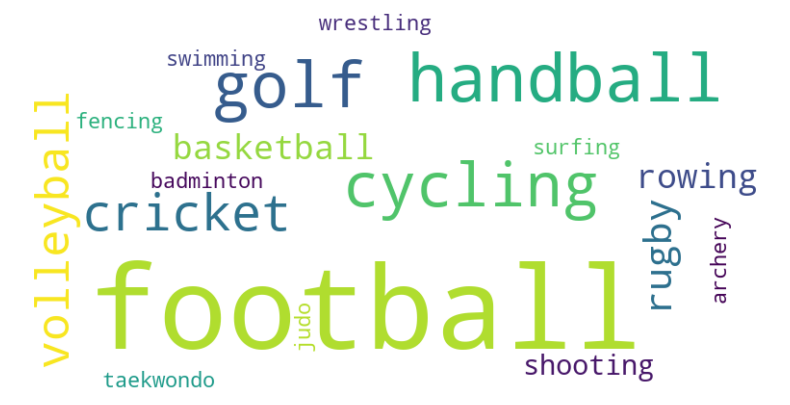

In [34]:
# Path to the CSV file with word counts
csv_file_path = 'cleaned_data/local/word_count_local.csv'

# Load data from CSV
df = pd.read_csv(csv_file_path)

# Convert DataFrame to dictionary with words as keys and counts as values
word_freq = dict(zip(df.Word, df.Count))

# Generate a word cloud image
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)

# Display the generated image using matplotlib
plt.figure(figsize=(10, 5))  # Adjust to appropriate dimensions
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # No axis for a cleaner presentation
plt.show()

<h3>UK</h3>

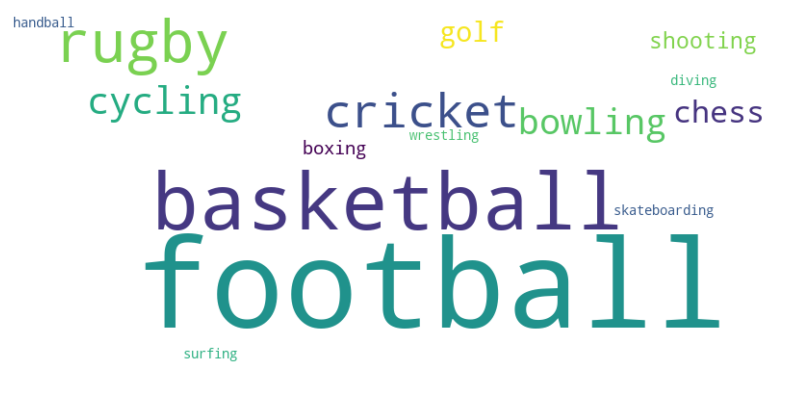

In [35]:
# Path to the CSV file with word counts
csv_file_path = 'cleaned_data/uk/word_count_uk.csv'

# Load data from CSV
df = pd.read_csv(csv_file_path)

# Convert DataFrame to dictionary with words as keys and counts as values
word_freq = dict(zip(df.Word, df.Count))

# Generate a word cloud image
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)

# Display the generated image using matplotlib
plt.figure(figsize=(10, 5))  # Adjust to appropriate dimensions
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # No axis for a cleaner presentation
plt.show()

<h3>US</h3>

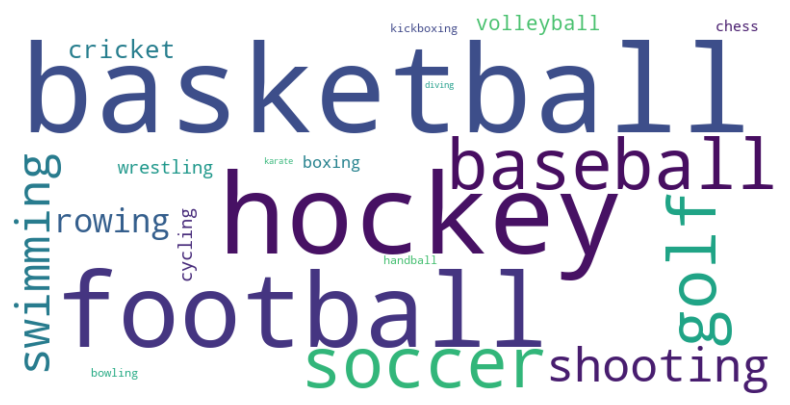

In [36]:
# Path to the CSV file with word counts
csv_file_path = 'cleaned_data/us/word_count_us.csv'

# Load data from CSV
df = pd.read_csv(csv_file_path)

# Convert DataFrame to dictionary with words as keys and counts as values
word_freq = dict(zip(df.Word, df.Count))

# Generate a word cloud image
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)

# Display the generated image using matplotlib
plt.figure(figsize=(10, 5))  # Adjust to appropriate dimensions
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # No axis for a cleaner presentation
plt.show()

<h4>4.2 Comparative Frequency Analysis between UK and Singapore</h4> 

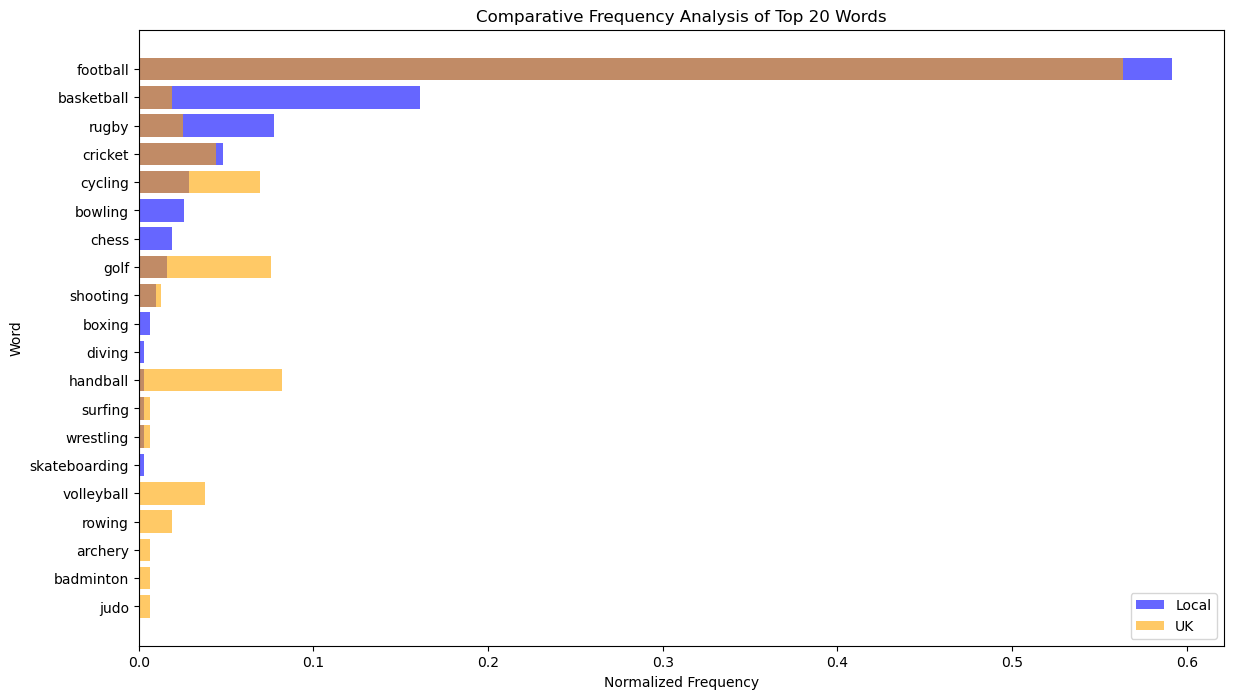

In [37]:
# Load the data from the provided CSV files
file_path_local = 'cleaned_data/uk/word_count_uk.csv'
file_path_uk = 'cleaned_data/local/word_count_local.csv'

df_local = pd.read_csv(file_path_local)
df_uk = pd.read_csv(file_path_uk)

# Merge the dataframes on the 'Word' column
df_merged = pd.merge(df_local, df_uk, on='Word', how='outer', suffixes=('_local', '_uk')).fillna(0)

# Calculate the total counts for normalization
total_local = df_local['Count'].sum()
total_uk = df_uk['Count'].sum()

# Normalize the counts
df_merged['Count_local_normalized'] = df_merged['Count_local'] / total_local
df_merged['Count_uk_normalized'] = df_merged['Count_uk'] / total_uk

# Sort by the local normalized count for better visualization
df_merged_sorted = df_merged.sort_values(by='Count_local_normalized', ascending=False).head(20)

# Plot the comparative frequency analysis
plt.figure(figsize=(14, 8))
plt.barh(df_merged_sorted['Word'], df_merged_sorted['Count_local_normalized'], color='blue', alpha=0.6, label='Local')
plt.barh(df_merged_sorted['Word'], df_merged_sorted['Count_uk_normalized'], color='orange', alpha=0.6, label='UK')
plt.xlabel('Normalized Frequency')
plt.ylabel('Word')
plt.title('Comparative Frequency Analysis of Top 20 Words')
plt.legend()
plt.gca().invert_yaxis()
plt.show()

The bar chart above provides a comparative frequency analysis of the top 20 words related to sports as mentioned in local and UK news outlets. The analysis highlights the normalized frequency of each word in both datasets, offering insights into the popularity and focus on different sports in these regions.<br>

<ul>
  <li><strong>Football</strong>: Significantly dominates in both local and UK news, with the highest normalized frequency. This indicates a strong interest and coverage in both regions.</li>
  <li><strong>Basketball</strong>: Shows a notable presence in local news, suggesting it is more popular or receives more attention locally compared to the UK.</li>
  <li><strong>Rugby</strong> and <strong>Cricket</strong>: These sports have higher frequencies in UK news, reflecting their greater popularity or coverage in the UK.</li>
  <li><strong>Cycling</strong> and <strong>Handball</strong>: More frequently mentioned in UK news, indicating a regional preference or higher media coverage.</li>
  <li><strong>Golf</strong> and <strong>Volleyball</strong>: Have a relatively balanced mention across both regions.</li>
  <li><strong>Sports like Diving, Surfing, Wrestling, and Skateboarding</strong>: These have lower frequencies but still appear in both datasets, showing some level of interest in both regions.</li>
</ul>
The chart uses normalized frequencies to account for the different total word counts in the datasets, ensuring a fair comparison. This visual representation helps identify the sports that are more prevalent in media coverage in each region, providing valuable insights into regional sports preferences and media focus.

<h3>6. Summary</h3>
<h4>6.1 Data analysis</h4>

From the data we have collected, both the UK and Singapore show a significant overlap in the populace's sport of choice, with football being the most reported sport in both regions. In contrast, the US demonstrates a distinct focus on basketball, hockey, and American football, reflecting the differing sports preferences among the populace.

The hypothesis suggests that the frequency with which a sport appears in a country's news outlets can serve as an accurate indicator of the sport's popularity among the populace. This correlation between media coverage and public interest highlights the role of news outlets in shaping and reflecting the sports preferences of a nation.

However, it is important to note that certain factors can skew the dataset, leading to an abnormal increase in the coverage of specific sports. Major sports events, such as the Euro 2024 and the Olympics, which are either ongoing or upcoming at the time of this analysis, can cause temporary spikes in the reporting of certain sports. These events draw significant media attention and public interest, potentially distorting the overall picture of sports popularity in a region.

<h4>6.2 Conclusions</h4>

In relation to this project on word analysis between news outlets, the analysis has identified certain sports that are frequently covered in Singaporean, UK, and US journalism. However, it is important to note that without a larger dataset, the conclusions drawn from our analysis may not be entirely definitive.

The current dataset, while informative, may be influenced by outliers which could potentially skew the data. These anomalies might result from the limited scope of the sample, affecting the accuracy and reliability of the findings. To mitigate this, a more extensive collection of articles from a wider range of sources and over a longer period would be necessary to ensure a more robust and representative analysis.

Expanding the dataset would allow for a more comprehensive examination of sports coverage patterns, reducing the impact of outliers and providing a clearer picture of the sports preferences in Singapore, the UK, and the US. This would ultimately enhance the validity of our comparative analysis and provide more conclusive insights into the similarities and differences in sports popularity between the three regions.

<h3>7. References and Resources</h3>
<h4>7.1 References</h4>

[1] The top publishers in Singapore for Q2 2023: https://www.newswhip.com/2023/07/the-top-publishers-in-singapore-for-q2-2023/ <br>
[2] Top 100 media outlets in the UK: https://prowly.com/profiles/outlet-lists/top-100-media-outlets-in-the-uk <br>
[3] Channel News Asia: https://www.channelnewsasia.com/ <br>
[4] The Straits Times: https://www.straitstimes.com/ <br>
[5] The Guardian (UK): https://www.theguardian.com/uk/ <br>
[6] Daily Mail: https://www.dailymail.co.uk/ <br>
[7] Fox News: https://www.foxnews.com/ <br>
[8] CNN Sports: https://edition.cnn.com/sport <br>
[9] theScore: https://www.thescore.com/ <br>

<h4>7.2 Resources</h4>

Bird, S., Klein, E., & Loper, E. (2023). Natural Language Toolkit. Retrieved from https://www.nltk.org/<br>
SeleniumHQ. (2023). Selenium WebDriver. Retrieved from https://www.selenium.dev/<br>
Python Software Foundation. (2023). Python Language Reference, version 3.9. Retrieved from https://www.python.org/<br>
The Pandas Development Team. (2023). Pandas: Python Data Analysis Library. Retrieved from https://pandas.pydata.org/<br>
Richardson, L. (2023). Beautiful Soup Documentation. Retrieved from https://www.crummy.com/software/BeautifulSoup/<br>